# Full model

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

In [44]:
# Parameters (TODO: replace placeholders; note units)
p = dict(
    r_growth   = 4.0,   # 1/time
    N_SI_max   = 10.0,   # carrying capacity
    I_max      = 0.0,   # max clearance rate (off for now)
    K_I        = 1.0,   # half-saturation for clearance
    f_free     = 0.3,   # fraction free, 0-1
    V_L        = 10.0,   # lumen volume (used if dynamic_VL is False)
    r_prod     = 2.0,   # T production per N_SI per time
    r_deg      = 1.0,   # 1/time
    k_max      = 1.0,   # 1/time
    K_T        = 1.0,   # half-saturation for T
    r_turnover = 0.5,   # 1/time
    Q0         = 10.0,   # baseline outflow, volume/time
    Q_max      = 100.0,   # max outflow, volume/time
    I0         = 10.0,   # baseline intake, volume/time
    eta        = 1.0,   # ORS replacement fraction
    t_R        = 20.0,   # ORS start time
    dynamic_VL = False, # True -> use state V in place of V_L in dN/dt
)

# Initial conditions [N_SI, T, E, V]
y0 = [1e-3, 0.0, 0.0, 1.0]
t_span = (0.0, 50.0)
t_eval = np.linspace(*t_span, 1000)

In [42]:
def Q_of(E, p):
    return p['Q0'] + (p['Q_max'] - p['Q0']) * E

def ORS_of(t, Q, p):
    return p['eta'] * Q * (t >= p['t_R'])   # u(t - t_R)

def rhs(t, y, p):
    N, T, E, V = y
    Q = Q_of(E, p)
    VL = V if p['dynamic_VL'] else p['V_L']
    dN = (p['r_growth'] * N * (1 - N / p['N_SI_max'])
          - p['I_max'] * N / (p['K_I'] + N)
          - p['f_free'] * Q * N / VL)
    dT = p['r_prod'] * N - p['r_deg'] * T
    dE = p['k_max'] * T / (p['K_T'] + T) * (1 - E) - p['r_turnover'] * E
    dV = ORS_of(t, Q, p) + p['I0'] - Q
    return [dN, dT, dE, dV]

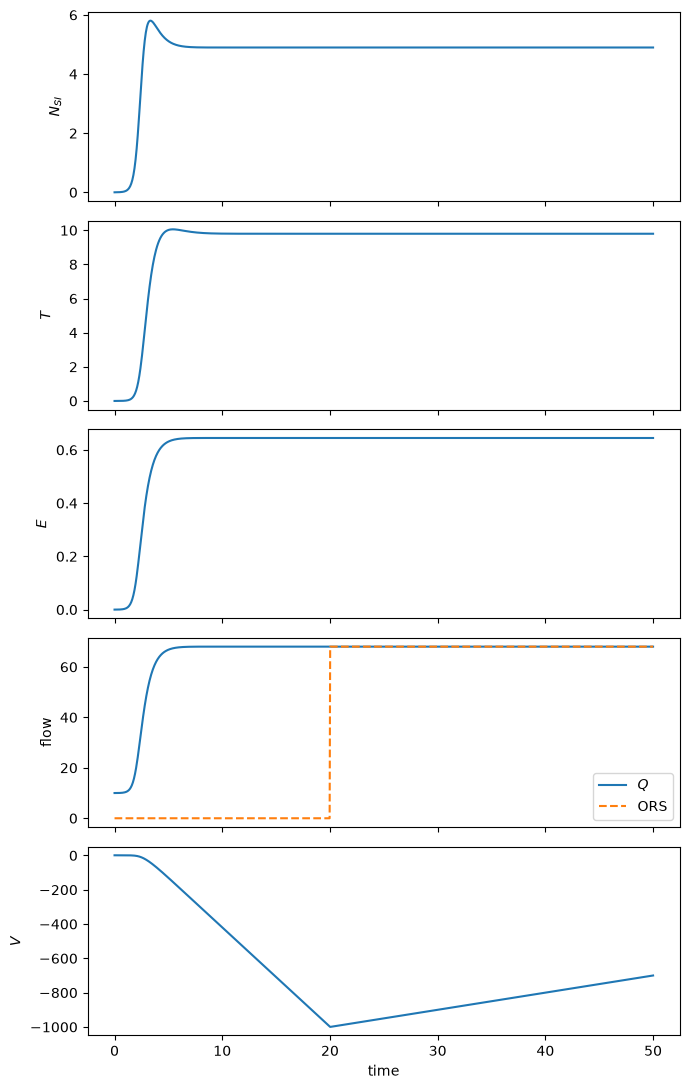

In [45]:
# max_step keeps the solver from stepping over the ORS switch at t_R
sol = solve_ivp(rhs, t_span, y0, args=(p,), t_eval=t_eval,
                method='LSODA', rtol=1e-8, atol=1e-12, max_step=0.1)

N, T, E, V = sol.y
Q = Q_of(E, p)
ORS = ORS_of(sol.t, Q, p)

fig, axs = plt.subplots(5, 1, figsize=(7, 11), sharex=True)
axs[0].plot(sol.t, N); axs[0].set_ylabel(r'$N_{SI}$')
axs[1].plot(sol.t, T); axs[1].set_ylabel(r'$T$')
axs[2].plot(sol.t, E); axs[2].set_ylabel(r'$E$')
axs[3].plot(sol.t, Q, label=r'$Q$'); axs[3].plot(sol.t, ORS, '--', label='ORS')
axs[3].set_ylabel('flow'); axs[3].legend()
axs[4].plot(sol.t, V); axs[4].set_ylabel(r'$V$')
axs[-1].set_xlabel('time')
plt.tight_layout(); plt.show()